DANE DO SLAJDU 1: ZBIÓR DANYCH
Typ problemu: Klasyfikacja obrazów (2 klasy)
Łączna liczba obrazów: 144 (Trening: 115, Walidacja: 29)
Klasa 'cracks': 68 obrazów (47.2%)
Klasa 'pothole': 76 obrazów (52.8%)


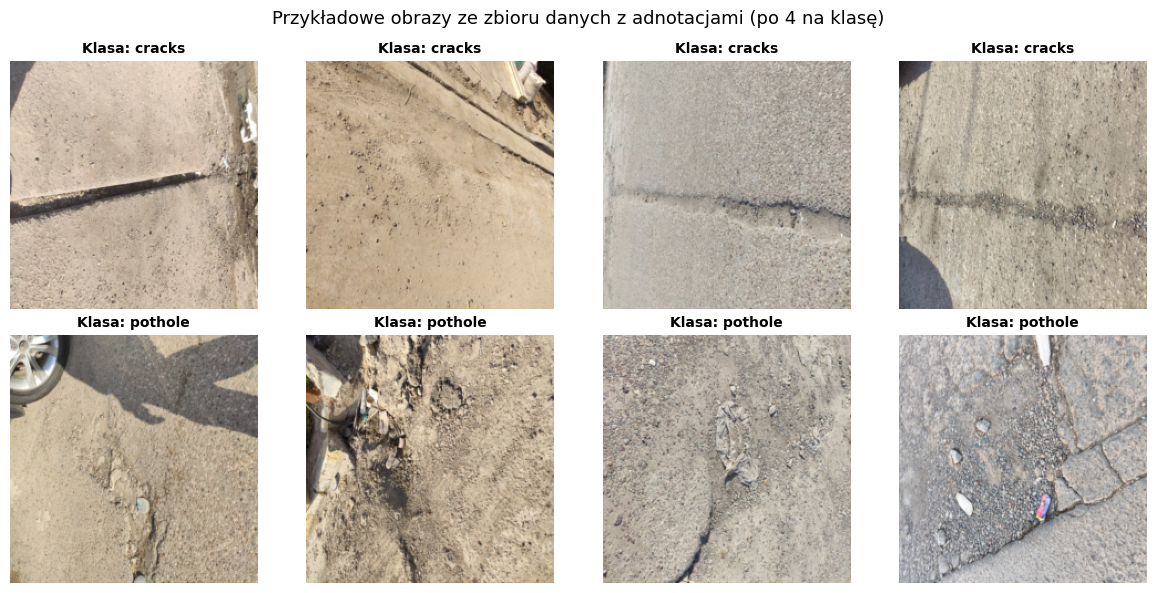


DANE DO SLAJDU 2: PLAN EKSPERYMENTU
Seed: 42 | Podział: 80/20 | Rozdzielczość: 224x224 px | Epoki: 10
Batch size: 32 | Optymalizator: Adam (lr=0.001) | Augmentacja: RandomHorizontalFlip
Konfiguracja 1 (K1): Wagi pretrenowane na ImageNet (Transfer Learning)
Konfiguracja 2 (K2): Trenowanie od zera (weights=None) przy identycznych pozostałych warunkach

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 122MB/s]


[1/6] Trening: resnet18 (11.18M param.) | K1 (Pretrenowane)
Wynik -> Acc: 0.7586 | F1: 0.7478 | Loss: 0.6589 | Czas: 259.0s
Macierz pomyłek:
[[14  1]
 [ 6  8]]
Szacowany czas do końca: 21 min 41 sek

[2/6] Trening: resnet18 (11.18M param.) | K2 (Od zera)
Wynik -> Acc: 0.7241 | F1: 0.7212 | Loss: 0.5306 | Czas: 254.7s
Macierz pomyłek:
[[12  3]
 [ 5  9]]
Szacowany czas do końca: 17 min 10 sek

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 98.7MB/s]


[3/6] Trening: mobilenet_v2 (2.23M param.) | K1 (Pretrenowane)
Wynik -> Acc: 0.7931 | F1: 0.7909 | Loss: 0.3970 | Czas: 266.0s
Macierz pomyłek:
[[13  2]
 [ 4 10]]
Szacowany czas do końca: 13 min 1 sek

[4/6] Trening: mobilenet_v2 (2.23M param.) | K2 (Od zera)
Wynik -> Acc: 0.5172 | F1: 0.3409 | Loss: 2.3913 | Czas: 266.7s
Macierz pomyłek:
[[15  0]
 [14  0]]
Szacowany czas do końca: 8 min 44 sek

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 137MB/s]


[5/6] Trening: efficientnet_b0 (4.01M param.) | K1 (Pretrenowane)
Wynik -> Acc: 0.7586 | F1: 0.7539 | Loss: 0.5396 | Czas: 266.2s
Macierz pomyłek:
[[ 9  6]
 [ 1 13]]
Szacowany czas do końca: 4 min 22 sek

[6/6] Trening: efficientnet_b0 (4.01M param.) | K2 (Od zera)
Wynik -> Acc: 0.4828 | F1: 0.3256 | Loss: 0.6932 | Czas: 265.6s
Macierz pomyłek:
[[ 0 15]
 [ 0 14]]
Szacowany czas do końca: 0 min 0 sek

DANE DO SLAJDU 3: PORÓWNANIE WSZYSTKICH TRENINGÓW
Architektura     | Konfig.           | Param.  | Acc    | Prec   | Rec    | F1     | Loss   | Trening | Inf/obr
----------------------------------------------------------------------------------------------------
resnet18         | K1 (Pretrenowane) | 11.18M | 0.7586 | 0.7944 | 0.7524 | 0.7478 | 0.6589 |  259.0s | 179.81ms
resnet18         | K2 (Od zera)      | 11.18M | 0.7241 | 0.7279 | 0.7214 | 0.7212 | 0.5306 |  254.7s | 157.05ms
mobilenet_v2     | K1 (Pretrenowane) |  2.23M | 0.7931 | 0.7990 | 0.7905 | 0.7909 | 0.3970 |  266.0s | 159.94

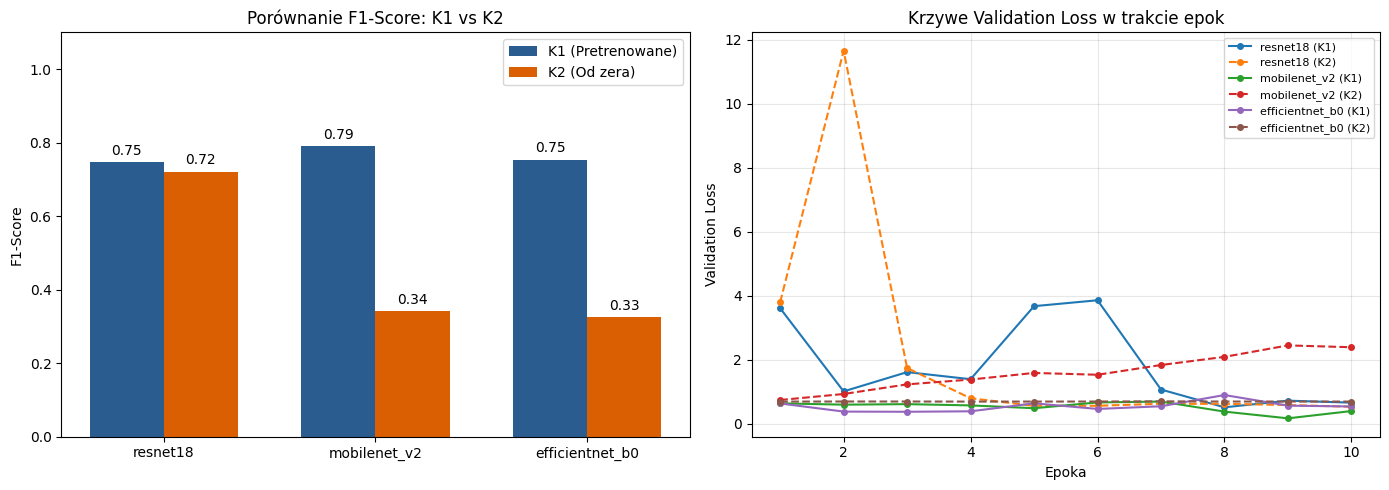

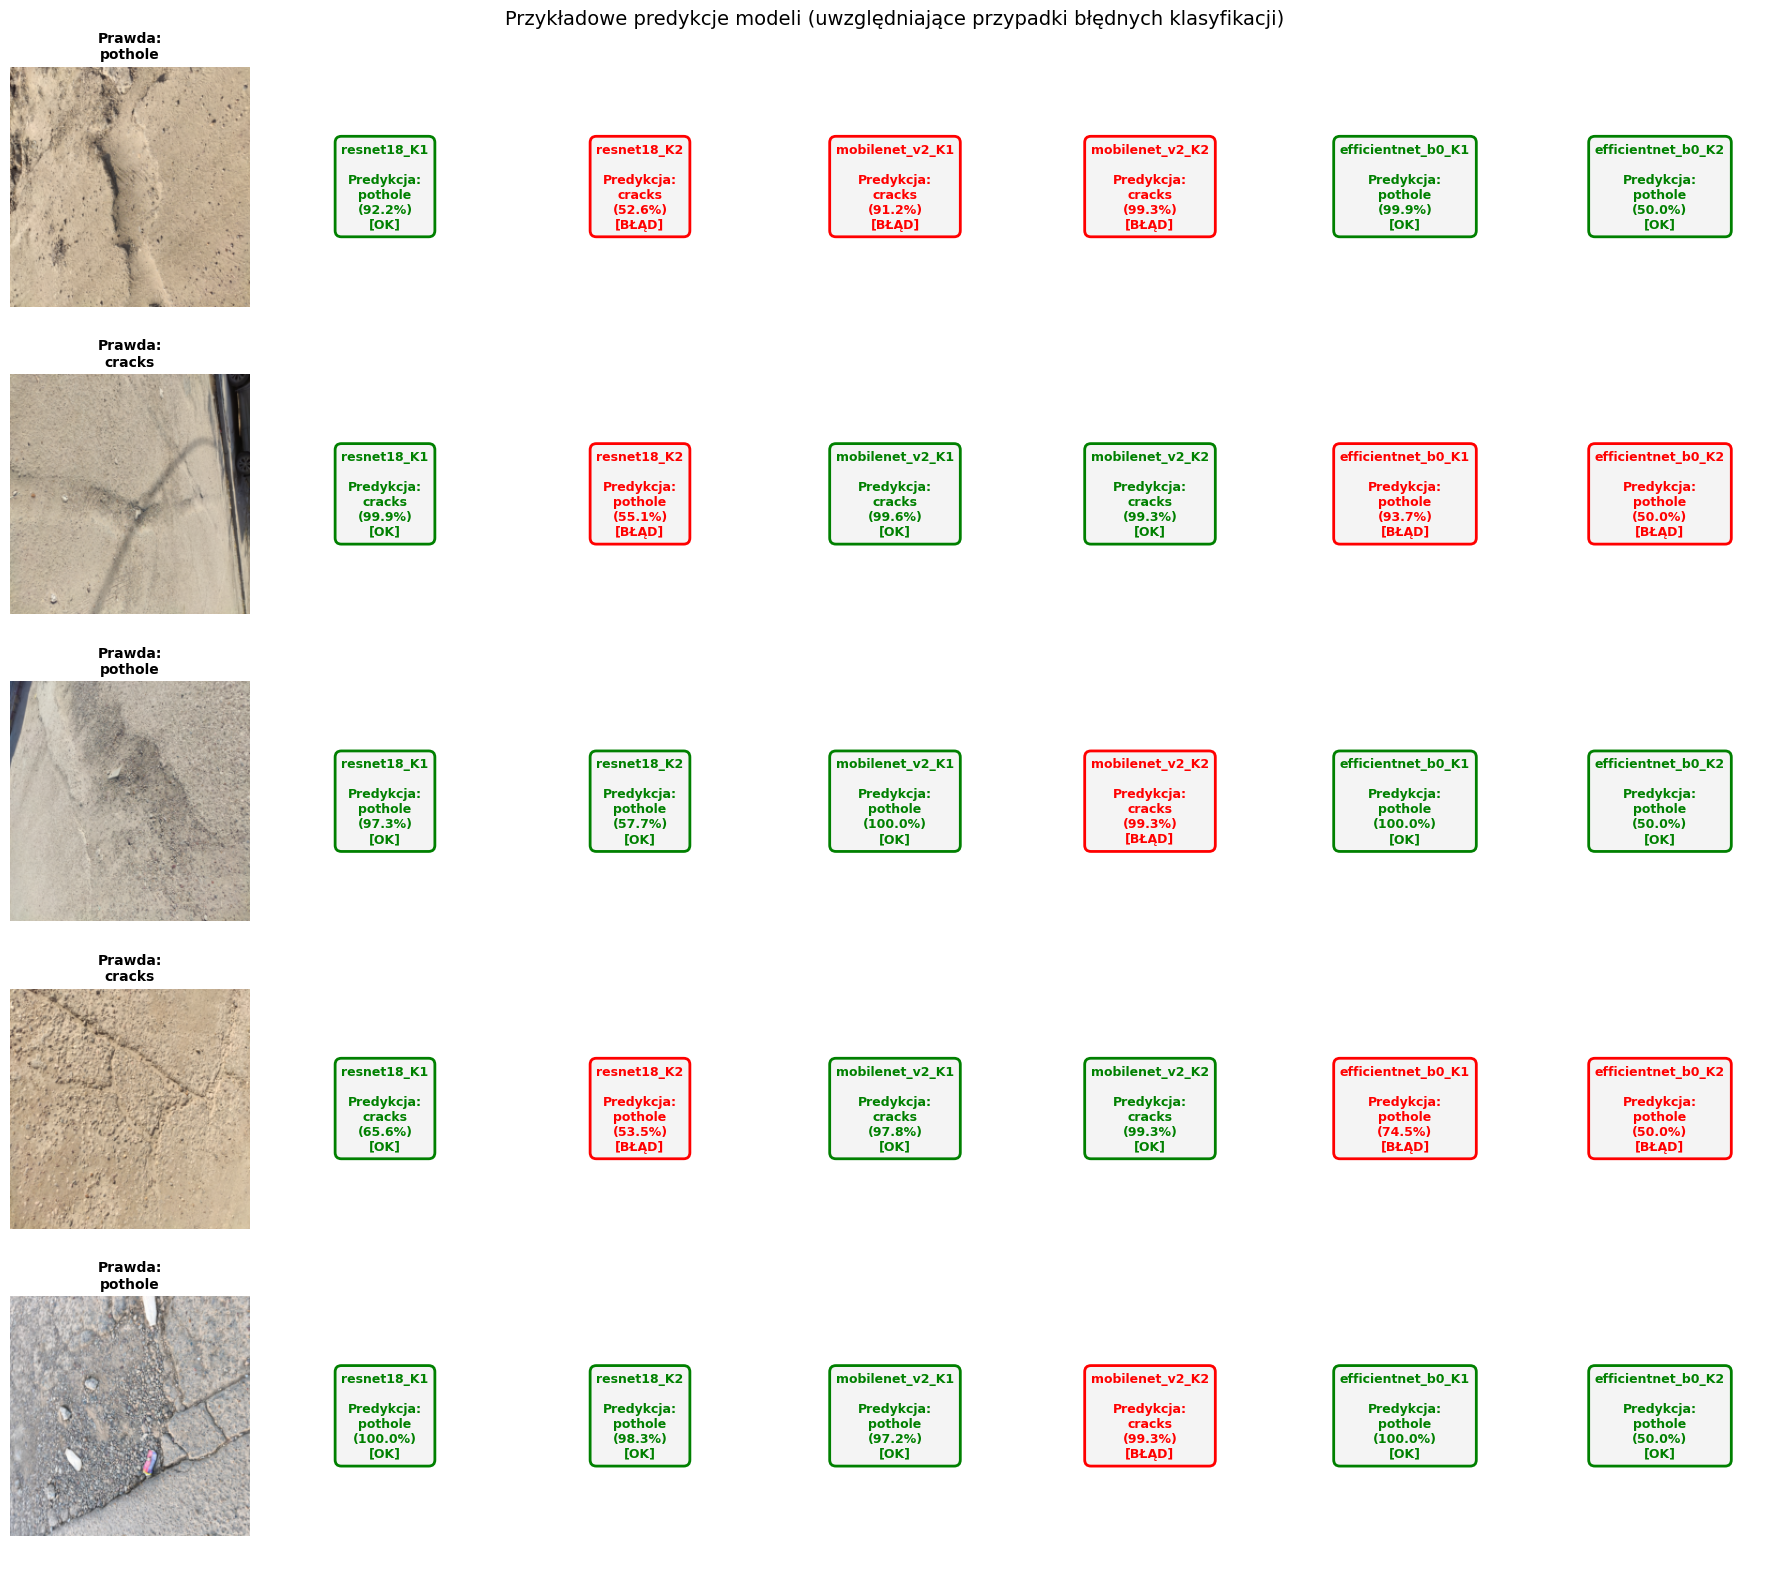


DANE DO SLAJDU 5: PODSUMOWANIE DO WNIOSKÓW
Najwyższa skuteczność (F1): mobilenet_v2 w konfiguracji K1 (Pretrenowane) (F1=0.7909, Acc=0.7931)
Najszybsza inferencja: resnet18 (157.05 ms/obraz, 11.18M parametrów)
Weryfikacja hipotezy (K1 vs K2): Średnie F1 dla wag pretrenowanych wynosi 0.7642, a dla treningu od zera 0.4625.
Zapisane pliki do pobrania: slajd1_probki_zbioru.png, slajd3_porownanie_modeli.png, slajd4_predykcje_i_bledy.png, wyniki_eksperymentow.csv


In [1]:
import os
import csv
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from PIL import ImageFile
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt

ImageFile.LOAD_TRUNCATED_IMAGES = True

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class SafeImageFolder(datasets.ImageFolder):
    def find_classes(self, directory):
        classes, _ = super().find_classes(directory)
        valid_classes = [c for c in classes if not c.startswith('.')]
        valid_class_to_idx = {c: i for i, c in enumerate(valid_classes)}
        return valid_classes, valid_class_to_idx

def unnormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.permute(1, 2, 0).cpu().numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)

# --- KONFIGURACJA EKSPERYMENTU ---
dataset_path = "/content/irak"
img_size = 224
batch_size = 32
epochs = 10
learning_rate = 0.001
seed = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

set_seed(seed)
dataset = SafeImageFolder(root=dataset_path, transform=transform)
class_names = dataset.classes
num_classes = len(class_names)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# --- DANE DO SLAJDU 1 I 2 ---
print("=" * 80)
print("DANE DO SLAJDU 1: ZBIÓR DANYCH")
print(f"Typ problemu: Klasyfikacja obrazów ({num_classes} klasy)")
print(f"Łączna liczba obrazów: {len(dataset)} (Trening: {train_size}, Walidacja: {val_size})")
counts = {name: 0 for name in class_names}
for _, label_idx in dataset.samples:
    counts[class_names[label_idx]] += 1
for name, count in counts.items():
    print(f"Klasa '{name}': {count} obrazów ({count/len(dataset)*100:.1f}%)")

# Generowanie po 4 przykładowe obrazy dla każdej klasy (Slajd 1)
fig, axes = plt.subplots(num_classes, 4, figsize=(12, 3 * num_classes))
if num_classes == 1:
    axes = np.expand_dims(axes, axis=0)

for row, class_idx in enumerate(range(num_classes)):
    class_indices = [i for i, (_, label) in enumerate(dataset.samples) if label == class_idx]
    selected = random.sample(class_indices, min(4, len(class_indices)))
    for col, idx in enumerate(selected):
        img, label = dataset[idx]
        axes[row, col].imshow(unnormalize(img))
        axes[row, col].set_title(f"Klasa: {class_names[label]}", fontsize=10, fontweight='bold')
        axes[row, col].axis('off')

plt.suptitle("Przykładowe obrazy ze zbioru danych z adnotacjami (po 4 na klasę)", fontsize=13)
plt.tight_layout()
plt.savefig("slajd1_probki_zbioru.png", dpi=150)
plt.show()

print("\n" + "=" * 80)
print("DANE DO SLAJDU 2: PLAN EKSPERYMENTU")
print(f"Seed: {seed} | Podział: 80/20 | Rozdzielczość: {img_size}x{img_size} px | Epoki: {epochs}")
print(f"Batch size: {batch_size} | Optymalizator: Adam (lr={learning_rate}) | Augmentacja: RandomHorizontalFlip")
print("Konfiguracja 1 (K1): Wagi pretrenowane na ImageNet (Transfer Learning)")
print("Konfiguracja 2 (K2): Trenowanie od zera (weights=None) przy identycznych pozostałych warunkach")
print("=" * 80 + "\n")

def get_model(arch_name, pretrained, num_outputs):
    if arch_name == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_outputs)
    elif arch_name == "mobilenet_v2":
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        model = models.mobilenet_v2(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_outputs)
    elif arch_name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_outputs)
    return model.to(device)

def train_and_evaluate(model, train_loader, val_loader, epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        history["train_loss"].append(running_loss / len(train_loader.dataset))

        model.eval()
        val_loss = 0.0
        correct = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
        history["val_loss"].append(val_loss / len(val_loader.dataset))
        history["val_acc"].append(correct / len(val_loader.dataset))

    # Końcowa ewaluacja i pomiar czasu inferencji
    model.eval()
    all_preds, all_labels = [], []
    inf_start = time.time()
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    inf_time_ms = ((time.time() - inf_start) / len(all_labels)) * 1000

    accuracy = np.mean(np.array(all_preds) == np.array(all_labels))
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average='macro', zero_division=0
    )
    cm = confusion_matrix(all_labels, all_preds)

    return {
        "loss": history["val_loss"][-1],
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "cm": cm,
        "inf_ms": inf_time_ms,
        "history": history
    }

architectures = ["resnet18", "mobilenet_v2", "efficientnet_b0"]
configs = [
    {"id": "K1", "name": "K1 (Pretrenowane)", "pretrained": True},
    {"id": "K2", "name": "K2 (Od zera)", "pretrained": False}
]

results_summary = []
trained_models = {}
total_iterations = len(architectures) * len(configs)
current_iteration = 0
start_time_total = time.time()

for arch in architectures:
    for config in configs:
        current_iteration += 1
        set_seed(seed)
        model = get_model(arch, config["pretrained"], num_classes)
        params_m = sum(p.numel() for p in model.parameters()) / 1e6

        print(f"[{current_iteration}/{total_iterations}] Trening: {arch} ({params_m:.2f}M param.) | {config['name']}")

        iter_start = time.time()
        metrics = train_and_evaluate(model, train_loader, val_loader, epochs)
        train_duration = time.time() - iter_start

        trained_models[f"{arch}_{config['id']}"] = model

        elapsed_total = time.time() - start_time_total
        eta = (elapsed_total / current_iteration) * (total_iterations - current_iteration)

        print(f"Wynik -> Acc: {metrics['accuracy']:.4f} | F1: {metrics['f1']:.4f} | Loss: {metrics['loss']:.4f} | Czas: {train_duration:.1f}s")
        print(f"Macierz pomyłek:\n{metrics['cm']}")
        print(f"Szacowany czas do końca: {int(eta // 60)} min {int(eta % 60)} sek\n")

        results_summary.append({
            "arch": arch,
            "config_id": config["id"],
            "config": config["name"],
            "params_m": params_m,
            "time": train_duration,
            **metrics
        })

# --- DANE DO SLAJDU 3: TABELA ZBIORCZA, CSV I WYKRESY ---
print("=" * 100)
print("DANE DO SLAJDU 3: PORÓWNANIE WSZYSTKICH TRENINGÓW")
print(f"{'Architektura':<16} | {'Konfig.':<17} | {'Param.':<7} | {'Acc':<6} | {'Prec':<6} | {'Rec':<6} | {'F1':<6} | {'Loss':<6} | {'Trening':<7} | {'Inf/obr':<7}")
print("-" * 100)
for r in results_summary:
    print(f"{r['arch']:<16} | {r['config']:<17} | {r['params_m']:>5.2f}M | {r['accuracy']:.4f} | {r['precision']:.4f} | {r['recall']:.4f} | {r['f1']:.4f} | {r['loss']:.4f} | {r['time']:>6.1f}s | {r['inf_ms']:>5.2f}ms")
print("=" * 100)

with open("wyniki_eksperymentow.csv", mode="w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Architektura", "Konfiguracja", "Parametry_M", "Accuracy", "Precision", "Recall", "F1_Score", "Val_Loss", "Czas_Treningu_s", "Inferencja_ms"])
    for r in results_summary:
        writer.writerow([r['arch'], r['config'], round(r['params_m'], 2), round(r['accuracy'], 4), round(r['precision'], 4), round(r['recall'], 4), round(r['f1'], 4), round(r['loss'], 4), round(r['time'], 1), round(r['inf_ms'], 2)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(architectures))
width = 0.35
f1_k1 = [r['f1'] for r in results_summary if r['config_id'] == 'K1']
f1_k2 = [r['f1'] for r in results_summary if r['config_id'] == 'K2']

rects1 = ax1.bar(x - width/2, f1_k1, width, label='K1 (Pretrenowane)', color='#2b5c8f')
rects2 = ax1.bar(x + width/2, f1_k2, width, label='K2 (Od zera)', color='#d95f02')
ax1.set_ylabel('F1-Score')
ax1.set_title('Porównanie F1-Score: K1 vs K2')
ax1.set_xticks(x)
ax1.set_xticklabels(architectures)
ax1.set_ylim(0, 1.1)
ax1.legend()
ax1.bar_label(rects1, fmt='%.2f', padding=3)
ax1.bar_label(rects2, fmt='%.2f', padding=3)

for r in results_summary:
    style = '-' if r['config_id'] == 'K1' else '--'
    ax2.plot(range(1, epochs + 1), r['history']['val_loss'], linestyle=style, marker='o', markersize=4, label=f"{r['arch']} ({r['config_id']})")
ax2.set_title('Krzywe Validation Loss w trakcie epok')
ax2.set_xlabel('Epoka')
ax2.set_ylabel('Validation Loss')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("slajd3_porownanie_modeli.png", dpi=150)
plt.show()

# --- DANE DO SLAJDU 4: PRZYKŁADOWE PREDYKCJE I BŁĘDY MODELI ---
error_indices = []
correct_indices = []

for idx in range(len(val_dataset)):
    img, true_label = val_dataset[idx]
    img_batch = img.unsqueeze(0).to(device)
    has_error = False
    for key, m in trained_models.items():
        m.eval()
        with torch.no_grad():
            pred = torch.argmax(m(img_batch), dim=1).item()
            if pred != true_label:
                has_error = True
    if has_error:
        error_indices.append(idx)
    else:
        correct_indices.append(idx)

selected_val_indices = error_indices[:3] + correct_indices[:2]
if len(selected_val_indices) < 5:
    remaining = [i for i in range(len(val_dataset)) if i not in selected_val_indices]
    selected_val_indices += remaining[:5 - len(selected_val_indices)]

num_samples = len(selected_val_indices)
fig, axes = plt.subplots(num_samples, 7, figsize=(18, 3.2 * num_samples))
if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

model_keys = list(trained_models.keys())

for row, val_idx in enumerate(selected_val_indices):
    img, true_label = val_dataset[val_idx]
    img_batch = img.unsqueeze(0).to(device)

    axes[row, 0].imshow(unnormalize(img))
    axes[row, 0].set_title(f"Prawda:\n{class_names[true_label]}", fontsize=10, fontweight='bold')
    axes[row, 0].axis('off')

    for col, key in enumerate(model_keys, start=1):
        m = trained_models[key]
        m.eval()
        with torch.no_grad():
            probs = F.softmax(m(img_batch), dim=1)
            conf, pred = torch.max(probs, 1)
            pred_idx = pred.item()
            conf_val = conf.item() * 100

        is_correct = (pred_idx == true_label)
        color = 'green' if is_correct else 'red'
        status = "OK" if is_correct else "BŁĄD"

        axes[row, col].text(0.5, 0.5, f"{key}\n\nPredykcja:\n{class_names[pred_idx]}\n({conf_val:.1f}%)\n[{status}]",
                            ha='center', va='center', fontsize=9, fontweight='bold', color=color,
                            bbox=dict(boxstyle='round,pad=0.5', facecolor='#f4f4f4', edgecolor=color, lw=2))
        axes[row, col].axis('off')

plt.suptitle("Przykładowe predykcje modeli (uwzględniające przypadki błędnych klasyfikacji)", fontsize=14)
plt.tight_layout()
plt.savefig("slajd4_predykcje_i_bledy.png", dpi=150)
plt.show()

# --- DANE DO SLAJDU 5: WNIOSKI ---
best_model = max(results_summary, key=lambda x: (x['f1'], x['accuracy']))
fastest_model = min(results_summary, key=lambda x: x['inf_ms'])
avg_f1_k1 = np.mean(f1_k1)
avg_f1_k2 = np.mean(f1_k2)

print("\n" + "=" * 80)
print("DANE DO SLAJDU 5: PODSUMOWANIE DO WNIOSKÓW")
print(f"Najwyższa skuteczność (F1): {best_model['arch']} w konfiguracji {best_model['config']} (F1={best_model['f1']:.4f}, Acc={best_model['accuracy']:.4f})")
print(f"Najszybsza inferencja: {fastest_model['arch']} ({fastest_model['inf_ms']:.2f} ms/obraz, {fastest_model['params_m']:.2f}M parametrów)")
print(f"Weryfikacja hipotezy (K1 vs K2): Średnie F1 dla wag pretrenowanych wynosi {avg_f1_k1:.4f}, a dla treningu od zera {avg_f1_k2:.4f}.")
print("Zapisane pliki do pobrania: slajd1_probki_zbioru.png, slajd3_porownanie_modeli.png, slajd4_predykcje_i_bledy.png, wyniki_eksperymentow.csv")
print("=" * 80)